In [85]:
!pip install fredapi #allowing python to access to FRED data

from fredapi import Fred #importing Fred tool from fredapi
import pandas as pd #importing pandas so we can use it for short as 'pd'
import matplotlib.pyplot as plt
import numpy as np


fred = Fred(api_key= 'YOUR KEY' ) #giving fred a variable name to be easier accessed and key so it could be used
cpi = fred.get_series("CPIAUCSL") # getting the cpi data from fred
print(cpi.head()) # .head() gives first 5 rows
print(cpi.tail()) # .tail() gives last 5 rows

1947-01-01    21.48
1947-02-01    21.62
1947-03-01    22.00
1947-04-01    22.00
1947-05-01    21.95
dtype: float64
2026-05-01    333.979
2026-06-01    332.568
2026-07-01    332.813
2026-08-01    334.131
2026-09-01    336.298
dtype: float64


In [86]:
print(type(cpi)) #checking to see if the type was right
print(len(cpi)) #telling you the length of the rows of cpi

<class 'pandas.core.series.Series'>
957


In [87]:
expected = fred.get_series('MICH') #getting the expected data from fred naming it expected
print(expected.head())
print(expected.tail())
print ('starts: ', expected.index.min()) #the starting date if the data
print ('ends: ', expected.index.max()) #ending date of the data
print ('rows: ', len(expected)) # number of rows of expected inflation data
print (type(expected)) #making sure the types of the two variables are the same

1978-01-01    5.2
1978-02-01    6.4
1978-03-01    6.3
1978-04-01    6.7
1978-05-01    6.9
dtype: float64
2026-05-01    4.8
2026-06-01    4.6
2026-07-01    4.2
2026-08-01    4.0
2026-09-01    4.6
dtype: float64
starts:  1978-01-01 00:00:00
ends:  2026-09-01 00:00:00
rows:  585
<class 'pandas.core.series.Series'>


In [88]:
print('CPI: ', cpi.index.min(), 'to', cpi.index.max()) #again comparing the length of the data because survey started later
print('Expected:', expected.index.min(), 'to', expected.index.max())


CPI:  1947-01-01 00:00:00 to 2026-09-01 00:00:00
Expected: 1978-01-01 00:00:00 to 2026-09-01 00:00:00


<Axes: title={'center': 'Expected Inflation% Progression'}, xlabel='Year', ylabel='Expected Inflation %'>

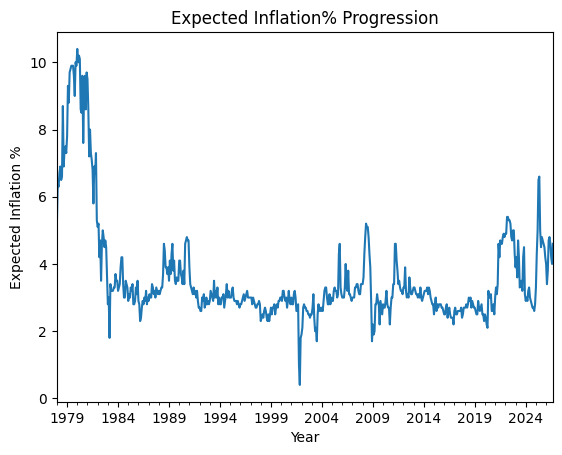

In [89]:
expected.plot(title= 'Expected Inflation% Progression', xlabel = 'Year', ylabel= 'Expected Inflation %')
#plotting the data for the expected list

In [90]:
cpi_year = cpi.pct_change(12)*100 #comparing the percent change in cpi with the values 12 rows before
expected_happen = expected.shift(12)
df = pd.concat([cpi_year, expected_happen, (cpi_year-expected_happen)], axis = 1, keys = ['cpi_year', 'expected','difference'])
#making a spread sheet called df with the two variables side by side
df = df.dropna() #deletes the data rows that are missing so future calculations will not be affected
print (df)

             cpi_year  expected  difference
1979-01-01   9.250399       5.2    4.050399
1979-02-01   9.841270       6.4    3.441270
1979-03-01  10.252366       6.3    3.952366
1979-04-01  10.485133       6.7    3.785133
1979-05-01  10.697674       6.9    3.797674
...               ...       ...         ...
2026-05-01   4.166615       6.6   -2.433385
2026-06-01   3.463531       5.0   -1.536469
2026-07-01   3.303856       4.5   -1.196144
2026-08-01   3.353016       4.8   -1.446984
2026-09-01   3.717251       4.7   -0.982749

[573 rows x 3 columns]


/tmp/ipykernel_820/2972237841.py:1: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  cpi_year = cpi.pct_change(12)*100 #comparing the percent change in cpi with the values 12 rows before


<Axes: title={'center': 'Inflation Progression'}>

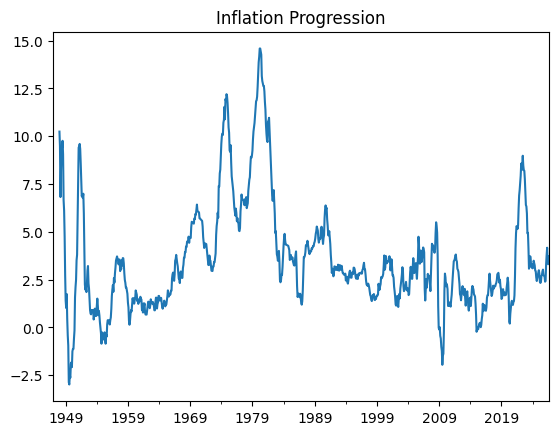

In [91]:
cpi_year.plot(title = 'Inflation Progression')

Text(0.5, 1.0, 'Expected vs actual inflation, 1979-2025')

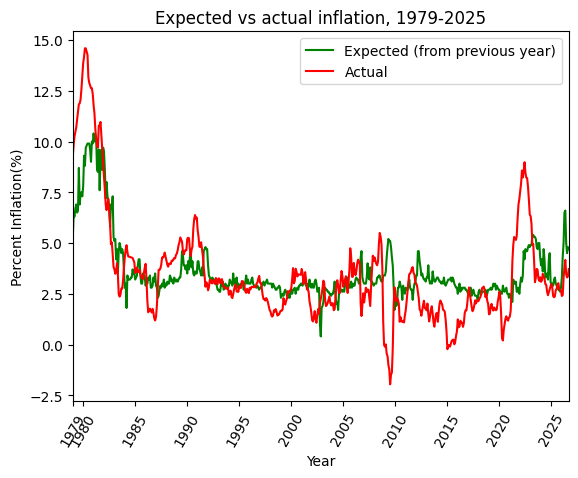

In [100]:
year = range(len(df)) # setting the x-axis to be the range of the number of rows in the data set
plt.plot(year, df.iloc[:, 1], label = 'Expected (from previous year)', color = 'green')
plt.plot(year, df.iloc[:, 0], label = 'Actual', color = 'red')
plt.xlim(0,len(df)-1)
plt.xticks((0,12,72,132,192,252,312,372,432,492,552), (1979,1980,1985,1990,1995,2000,2005,2010,2015,2020,2025))
#making it so that the x axis ticks are in years that ends in 5 or 0 for visual, besides 1978 because that is the starting month
plt.xticks(rotation = 60) # so that the years wouldn't overlap
plt.legend(loc = 'upper right', fontsize = 10)
plt.xlabel('Year')
plt.ylabel('Percent Inflation(%)')
plt.title('Expected vs actual inflation, 1979-2025')

(array([  0,  12,  72, 132, 192, 252, 312, 372, 432, 492, 552]),
 [Text(0, 0, '1979'),
  Text(12, 0, '1980'),
  Text(72, 0, '1985'),
  Text(132, 0, '1990'),
  Text(192, 0, '1995'),
  Text(252, 0, '2000'),
  Text(312, 0, '2005'),
  Text(372, 0, '2010'),
  Text(432, 0, '2015'),
  Text(492, 0, '2020'),
  Text(552, 0, '2025')])

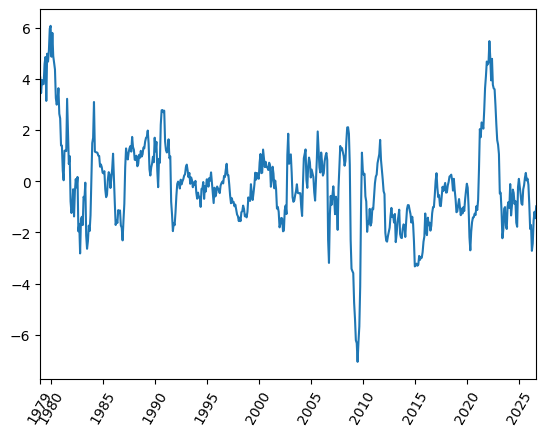

In [93]:
plt.plot(year, df.iloc[:,2]) #difference plot
plt.xlim(0,len(df)-1)
plt.xticks((0,12,72,132,192,252,312,372,432,492,552), (1979,1980,1985,1990,1995,2000,2005,2010,2015,2020,2025))
plt.xticks(rotation = 60)

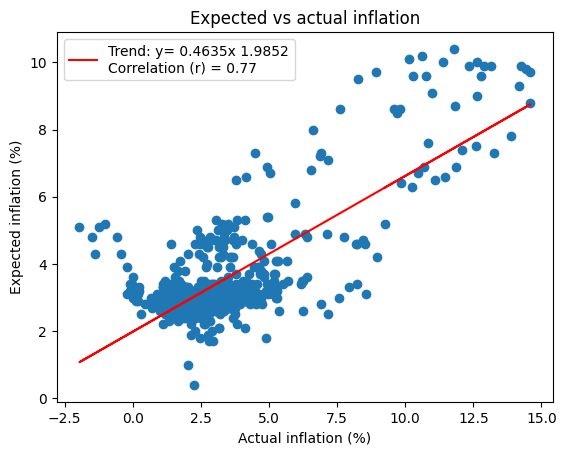

In [94]:
plt.scatter(df.iloc[:,0],df.iloc[:,1])
plt.xlabel("Actual inflation (%)")
plt.ylabel("Expected inflation (%)")
plt.title("Expected vs actual inflation")
x = df.iloc[:,0] # setting x to be the list of actual inflation
y = df.iloc[:,1] # setting y to be the list of expected inflation
m, b = np.polyfit(x, y, 1) #finding the line of best fit where y= b+mx, degree 1
r = np.corrcoef(x,y)[0,1] # finding correlation coefficient
plt.plot(x, m*x + b, color = 'red', label = f'Trend: y= {m:.4f}x {b:.4f}\nCorrelation (r) = {r:.2f}')
plt.legend(loc= 'upper left')

In [95]:
import sqlite3
conx = sqlite3.connect('inflation.db')
df.to_sql('monthly', conx, if_exists = 'replace', index_label='date') #importing to SQL as data table for later actions

573

In [96]:
ten_highest_expected = pd.read_sql("SELECT date, expected FROM monthly ORDER BY expected DESC LIMIT 10",conx)
average_of_two = pd.read_sql("SELECT AVG(expected - cpi_year) AS avg_gap FROM monthly",conx)
expect_more_2_actual = pd.read_sql("SELECT * FROM monthly WHERE (expected - cpi_year) >= 2",conx)
# could replace what in the " " with your own query

In [97]:
print(ten_highest_expected) # the 10 months with the highest expected inflation

                  date  expected
0  1981-01-01 00:00:00      10.4
1  1981-03-01 00:00:00      10.2
2  1981-04-01 00:00:00      10.1
3  1980-11-01 00:00:00      10.0
4  1981-02-01 00:00:00      10.0
5  1980-06-01 00:00:00       9.9
6  1980-07-01 00:00:00       9.9
7  1980-08-01 00:00:00       9.9
8  1980-12-01 00:00:00       9.9
9  1980-05-01 00:00:00       9.8


In [98]:
print(average_of_two) # the average of the inflation between the expected and actual

    avg_gap
0  0.113852


In [99]:
print(expect_more_2_actual) # the months where the expected inflation was higher by 2 points than actual

                   date  cpi_year  expected  difference
0   1982-11-01 00:00:00  4.477612       7.3   -2.822388
1   1983-06-01 00:00:00  2.474227       4.6   -2.125773
2   1983-07-01 00:00:00  2.358974       5.0   -2.641026
3   1983-08-01 00:00:00  2.456499       4.8   -2.343501
4   1986-12-01 00:00:00  1.187215       3.5   -2.312785
5   2006-09-01 00:00:00  2.012072       4.3   -2.287928
6   2006-10-01 00:00:00  1.406328       4.6   -3.193672
7   2008-11-01 00:00:00  1.099917       3.4   -2.300083
8   2008-12-01 00:00:00 -0.022228       3.4   -3.422228
9   2009-01-01 00:00:00 -0.113586       3.4   -3.513586
10  2009-02-01 00:00:00  0.008463       3.6   -3.591537
11  2009-03-01 00:00:00 -0.446479       4.3   -4.746479
12  2009-04-01 00:00:00 -0.576324       4.8   -5.376324
13  2009-05-01 00:00:00 -1.015761       5.2   -6.215761
14  2009-06-01 00:00:00 -1.229175       5.1   -6.329175
15  2009-07-01 00:00:00 -1.958761       5.1   -7.058761
16  2009-08-01 00:00:00 -1.483836       4.8   -6